In [11]:
import numpy as np
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [12]:
faces = fetch_olivetti_faces()

X_train, X_test, y_train, y_test = train_test_split(
    faces.data.astype(np.float64),
    faces.target,
    test_size=0.3,
    stratify=faces.target,
    random_state=0,
)

print(X_train.shape, X_test.shape)  # (280, 4096) (120, 4096)

(280, 4096) (120, 4096)


## B1

## Question 1

Total images:       400
Image size:         (64, 64) -> 4096 pixels per image
Number of classes:  40
Pixel range:        0.0 to 1.0
Train / test:       (280, 4096) (120, 4096)
Images per class (total): 10 - 10
Train images per class:   {np.int64(7)}
Test images per class:    {np.int64(3)}


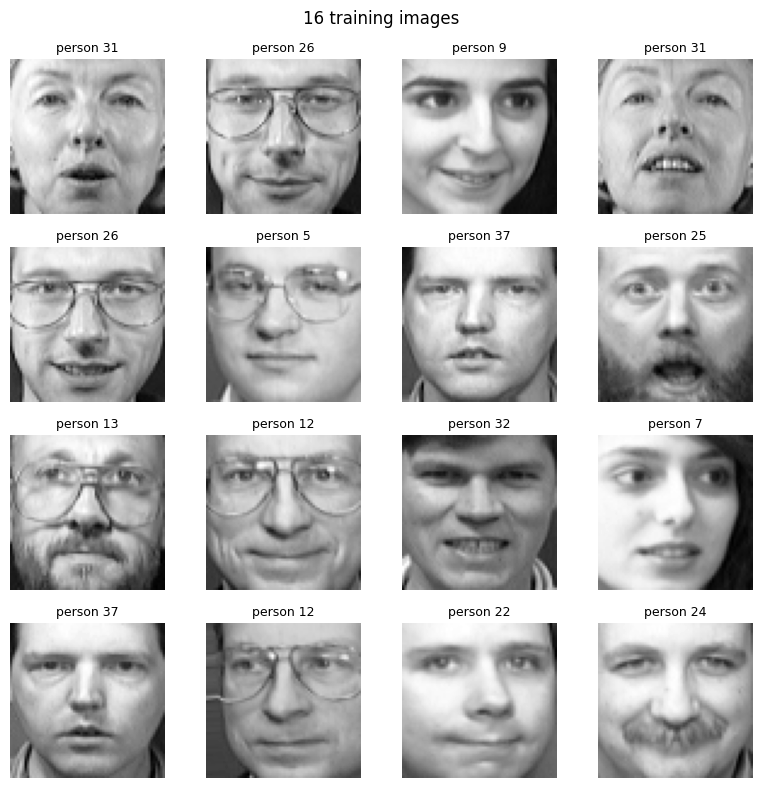

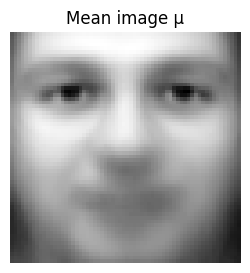

In [13]:
# Dataset description 
print("Total images:      ", faces.images.shape[0])
print("Image size:        ", faces.images.shape[1:], "->", faces.data.shape[1], "pixels per image")
print("Number of classes: ", len(np.unique(faces.target)))
print("Pixel range:       ", faces.data.min(), "to", faces.data.max())
print("Train / test:      ", X_train.shape, X_test.shape)

classes, train_counts = np.unique(y_train, return_counts=True)
_, test_counts = np.unique(y_test, return_counts=True)
print("Images per class (total):", np.bincount(faces.target).min(), "-", np.bincount(faces.target).max())
print("Train images per class:  ", set(train_counts))
print("Test images per class:   ", set(test_counts))

#16 training images
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i].reshape(64, 64), cmap="gray")
    ax.set_title(f"person {y_train[i]}", fontsize=9)
    ax.axis("off")
fig.suptitle("16 training images")
plt.tight_layout()
plt.show()

# Mean image μ (computed on the training set)
mu = X_train.mean(axis=0)
plt.figure(figsize=(3, 3))
plt.imshow(mu.reshape(64, 64), cmap="gray")
plt.title("Mean image μ")
plt.axis("off")
plt.show()

## 2.


(4096, 280) (280,) (280, 280)
Components for 90% variance: 60
Components for 95% variance: 105


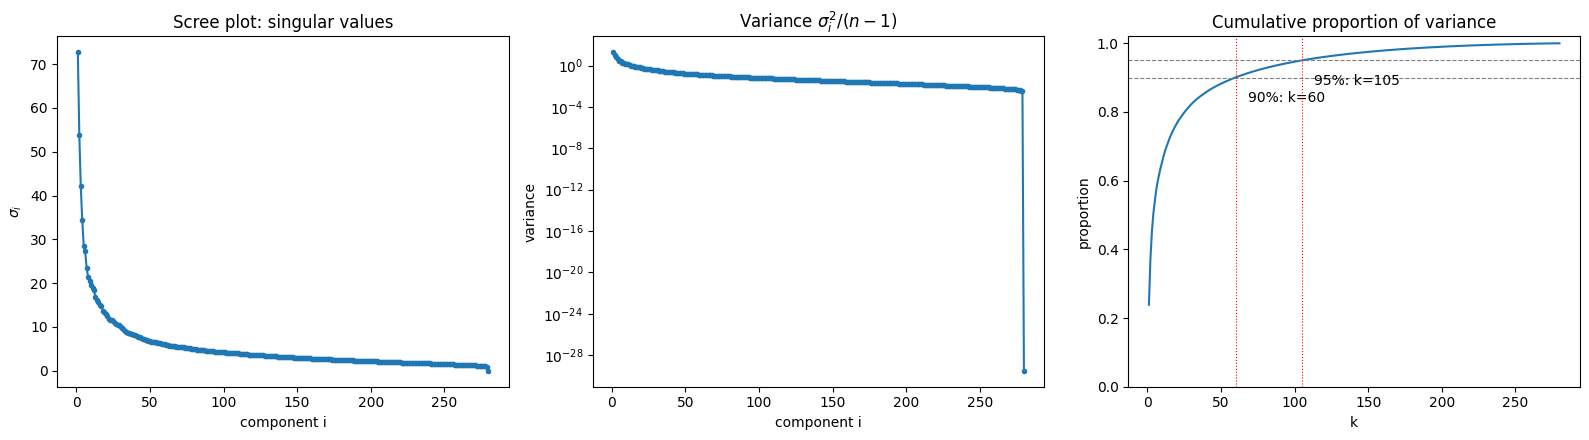

In [14]:
# A: centered training data
mu = X_train.mean(axis=0)
A = (X_train - mu).T
n = A.shape[1]                                   # 280

# Thin SVD: A = U @ diag(s) @ Vt
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print(U.shape, s.shape, Vt.shape)                # (4096, 280) (280,) (280, 280)

# Variance of each principal component and cumulative proportion
var = s**2 / (n - 1)
cum = np.cumsum(var) / var.sum()
k = np.arange(1, len(s) + 1)

k90 = int(np.searchsorted(cum, 0.90) + 1)
k95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"Components for 90% variance: {k90}")
print(f"Components for 95% variance: {k95}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].plot(k, s, "o-", ms=3)
ax[0].set(title="Scree plot: singular values", xlabel="component i", ylabel=r"$\sigma_i$")

ax[1].plot(k, var, "o-", ms=3)
ax[1].set(title=r"Variance $\sigma_i^2/(n-1)$", xlabel="component i", ylabel="variance")
ax[1].set_yscale("log")

ax[2].plot(k, cum, "-")
for p, kk in [(0.90, k90), (0.95, k95)]:
    ax[2].axhline(p, color="gray", ls="--", lw=0.8)
    ax[2].axvline(kk, color="red", ls=":", lw=0.8)
    ax[2].annotate(f"{int(p*100)}%: k={kk}", (kk, p), xytext=(kk + 8, p - 0.07))
ax[2].set(title="Cumulative proportion of variance", xlabel="k", ylabel="proportion", ylim=(0, 1.02))

plt.tight_layout()
plt.show()

#### The first 60 principal components capture 90% of the total variance and the first 105 capture 95%, so the 4096-dimensional images lie close to a subspace of roughly 1-3% of the original dimension. ####

## Question 3

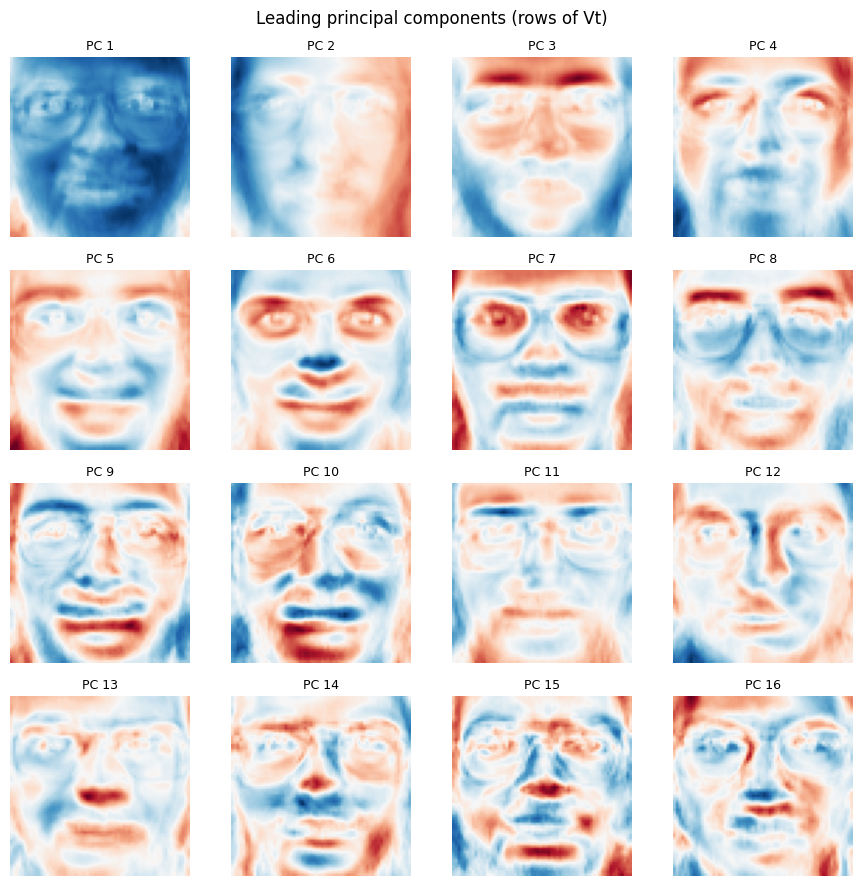

PC  1: highest person 21 (+9.52), lowest person  5 (-8.86)
PC  2: highest person 23 (+4.21), lowest person  7 (-6.82)
PC  3: highest person 36 (+4.85), lowest person 23 (-4.03)
PC  4: highest person 18 (+3.31), lowest person 32 (-3.39)
PC  5: highest person 34 (+2.98), lowest person 28 (-2.90)
PC  6: highest person 37 (+2.80), lowest person 11 (-2.59)
PC  7: highest person  1 (+2.22), lowest person 23 (-2.33)
PC  8: highest person  1 (+2.49), lowest person 10 (-2.70)
PC  9: highest person 19 (+1.67), lowest person 14 (-1.92)
PC 10: highest person 33 (+1.64), lowest person 16 (-1.69)
PC 11: highest person 19 (+2.44), lowest person 27 (-2.90)
PC 12: highest person  6 (+1.63), lowest person 10 (-1.42)
PC 13: highest person  9 (+1.62), lowest person 32 (-1.98)
PC 14: highest person 13 (+1.81), lowest person 18 (-1.57)
PC 15: highest person 33 (+1.60), lowest person 36 (-1.46)
PC 16: highest person  7 (+1.02), lowest person  6 (-1.97)


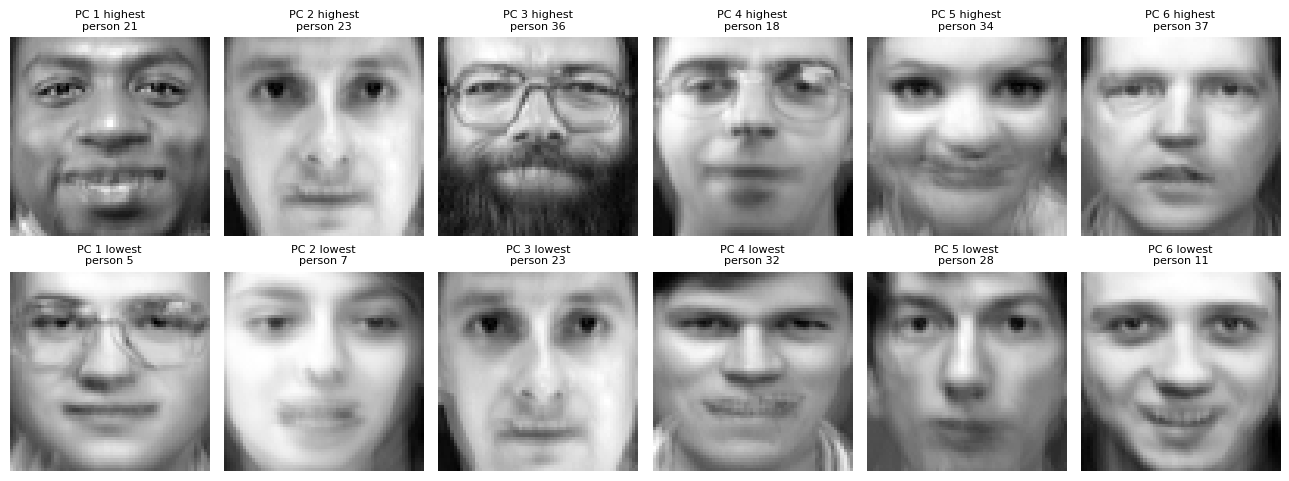

In [15]:
#16 leading principal components as images (diverging colormap) 
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.ravel()):
    comp = U[:, i].reshape(64,64)
    m = np.abs(comp).max()                      # symmetric limits so 0 = white
    ax.imshow(comp, cmap="RdBu_r", vmin=-m, vmax=m)
    ax.set_title(f"PC {i+1}", fontsize=9)
    ax.axis("off")
fig.suptitle("Leading principal components (rows of Vt)")
plt.tight_layout()
plt.show()

# Average score of each person on each component 
scores =  U.T @ A                               # shape (280, 280)
persons = np.unique(y_train)
mean_scores = np.array([scores[:16, y_train==p].mean(axis=1) for p in persons])  # (40, 16)

for i in range(16):
    hi = persons[np.argmax(mean_scores[:, i])]
    lo = persons[np.argmin(mean_scores[:, i])]
    print(f"PC {i+1:2d}: highest person {hi:2d} ({mean_scores[hi, i]:+.2f}), "
          f"lowest person {lo:2d} ({mean_scores[lo, i]:+.2f})")

#Show the extreme people for the first 6 components
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for i in range(6):
    hi = persons[np.argmax(mean_scores[:, i])]
    lo = persons[np.argmin(mean_scores[:, i])]
    for row, (p, lab) in enumerate([(hi, "highest"), (lo, "lowest")]):
        axes[row, i].imshow(X_train[y_train == p].mean(axis=0).reshape(64, 64), cmap="gray")
        axes[row, i].set_title(f"PC {i+1} {lab}\nperson {p}", fontsize=8)
        axes[row, i].axis("off")
plt.tight_layout()
plt.show()

#### The leading components capture mostly illumination and global appearance. PC 1 is an overall brightness/skin-tone component: the dark-skinned person 21 has the highest mean score and the brightly lit person 5 has the lowest. PC 2 is a left-right illumination contrast (highest person 23, lowest person 7). PC 3 contrasts the forehead and hair against the lower face and beard, with the bearded, bespectacled person 36 at the highest end and person 23 at the lowest. PC 5 and PC 6 concentrate on the mouth and lower face. Their between-person share is only 28% and 32%, below the 37% average over PCs 1-20, so they reflect expression, mouth shape and lower-face lighting that vary within a person's photos as well as between people. PC 7-9 show ring-shaped patterns around the eyes consistent with glasses, with persons 1, 10 and 19 among the extremes. Later components (PC 10-16) are increasingly localised and fine-grained, capturing details of the eyes, nose and mouth. Overall, the first components are dominated by lighting and imaging conditions rather than identity, and the identity-specific information is spread across many components. The sign of each component is arbitrary, so the highest/lowest labels describe a contrast between the two extremes, not "high means X".

## Question 4

### *Part a*

### Since U<sub>k</sub> has orthonormal columns, P = U<sub>k</sub> U<sub>k</sub> ᵀ is the orthogonal projector onto span(u₁, …, u<sub>k</sub> ). Column j of A<sub>k</sub>  is P·a<sub>j</sub> , where a<sub>j</sub> is the j-th centred image. So A<sub>k</sub>  replaces each centred image by its orthogonal projection onto the span of the first k principal components. Adding μ back gives the reconstructed face

### *Part b*

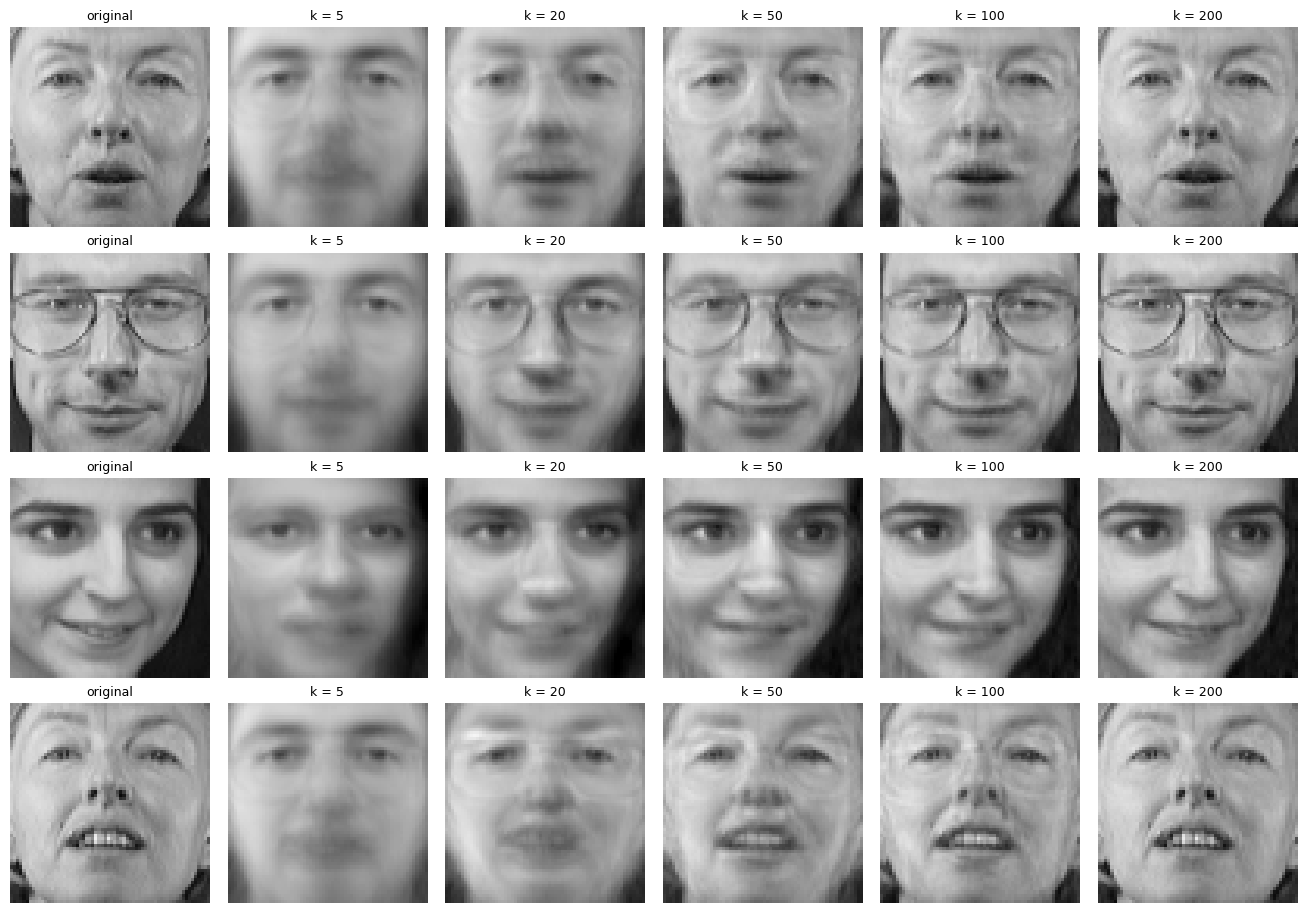

In [16]:
idx = [0, 1, 2, 3]                      # four training images
ks = [5, 20, 50, 100, 200]

fig, axes = plt.subplots(len(idx), len(ks) + 1, figsize=(2.2 * (len(ks) + 1), 2.3 * len(idx)))
for r, i in enumerate(idx):
    axes[r, 0].imshow(X_train[i].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_title("original", fontsize=9)
    for c, k in enumerate(ks, start=1):
        Vk = Vt[:k].T                                   # (4096, k)
        rec = mu + U[:, :k] @ (U[:, :k].T @ A[:, i])                   # projection onto first k PCs, plus mean
        axes[r, c].imshow(rec.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"k = {k}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

### *Part c*

In [17]:
ks_check = [1, 5, 20, 60, 105, 200, 279]
total = np.linalg.norm(A, "fro")**2
rng = np.random.default_rng(0)

print(f"{'k':>4} {'||A-Ak||_F^2':>14} {'sum_{i>k} s_i^2':>16} {'rel. diff':>10} {'1-cum(k)':>9} {'random rank-k':>14}")
for k in ks_check:
    Ak = (U[:, :k] * s[:k]) @ Vt[:k]
    lhs = np.linalg.norm(A - Ak, "fro")**2
    rhs = (s[k:]**2).sum()

    # comparison: project onto a random k-dim subspace (also rank <= k)
    Q, _ = np.linalg.qr(rng.standard_normal((A.shape[1], k)))
    lhs_rand = np.linalg.norm(A - A @ Q @ Q.T, "fro")**2

    print(f"{k:>4} {lhs:>14.4f} {rhs:>16.4f} {abs(lhs-rhs)/max(rhs,1e-12):>10.1e} "
          f"{rhs/total:>9.4f} {lhs_rand:>14.2f}")

   k   ||A-Ak||_F^2  sum_{i>k} s_i^2  rel. diff  1-cum(k)  random rank-k
   1     16833.0926       16833.0926    2.2e-16    0.7611       22048.54
   5     10161.7367       10161.7367    5.4e-16    0.4595       21782.17
  20      5144.9388        5144.9388    0.0e+00    0.2326       20362.27
  60      2191.9764        2191.9764    2.1e-16    0.0991       17155.20
 105      1098.9922        1098.9922    0.0e+00    0.0497       13774.24
 200       221.1186         221.1186    3.9e-16    0.0100        6228.12
 279         0.0000           0.0000    1.2e-13    0.0000          65.07


### Eckart–Young says that among all matrices of rank at most k, the truncated SVD A<sub>k</sub> is closest to A in Frobenius norm, with squared error equal to the discarded Σ<sub>{i>k}</sub> σᵢ². A rank-≤k matrix B has all its columns in some k-dimensional subspace, so choosing B amounts to choosing a subspace and approximating each centred image by a point in it. The best point is the orthogonal projection, so ‖A − B‖²<sub>F</sub> is the total squared distance from the images to that subspace. The theorem says no k-dimensional subspace does better than span(u₁, …, u<sub>k</sub> ), which is exactly the subspace PCA picks. Since ‖A‖²<sub>F</sub> is fixed (retained plus lost), minimising the lost part is the same as maximising the retained variance, the usual PCA criterion. And because we subtract μ first, PCA is really the best k-dimensional affine approximation through the data mean. The theorem also prices each truncation exactly (the discarded σᵢ²), which is what the scree and cumulative-variance plots show.

## Question 5

std range: 0.089 to 0.218, ratio max/min = 2.5


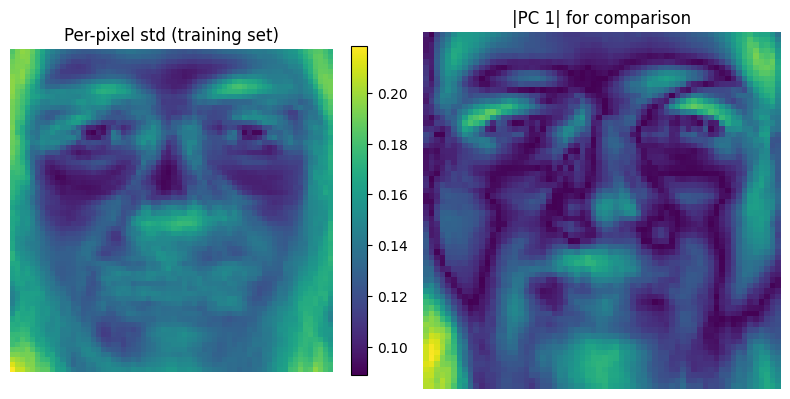

In [18]:
sd = X_train.std(axis=0, ddof=1)          # per-pixel std across the 280 training images
print(f"std range: {sd.min():.3f} to {sd.max():.3f}, ratio max/min = {sd.max()/sd.min():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
im = ax[0].imshow(sd.reshape(64, 64), cmap="viridis")
ax[0].set_title("Per-pixel std (training set)"); ax[0].axis("off")
plt.colorbar(im, ax=ax[0], fraction=0.046)

ax[1].imshow(np.abs(U[:, i].reshape(64,64)), cmap="viridis")
ax[1].set_title("|PC 1| for comparison"); ax[1].axis("off")
plt.tight_layout(); plt.show()

### In the breast cancer data, standardization was necessary because the 30 features are measured in different units and their raw variances differ by orders of magnitude, so unscaled PCA would be dominated by the area features (in Part A Q4, worst area has a loading of about 0.85 and mean area about 0.52 on the first component), simply because area has by far the largest numeric scale. In the faces data all features are pixel intensities on the same [0, 1] scale, and differences in per-pixel standard deviation reflect real variation (hair, eyes, mouth), so we only centre the data. The per-pixel standard deviation map shows values between 0.089 and 0.218 (max/min ratio of only 2.5), with the highest variability at the left and right edges and corners of the image, where hair and background change between photos, and moderately high values around the eyebrows and eyes and across the mouth region, while the nose bridge and cheeks are the most stable. Since all pixels have the same units and a similar spread, standardizing would not fix a scale problem, and it would remove the real differences in variability between regions. The rule is to standardize when features have incompatible scales and not when they share a common, meaningful scale. So no, we should not standardize each pixel to mean 0 and standard deviation 1 before PCA here.